In [ ]:
#!pip install onnxruntime onnxscript onnxruntime-tools onnx segmentation-models-pytorch torch 

# Setup

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '5'

import random
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large
from tqdm import tqdm
from onnxruntime.quantization import quantize_dynamic, QuantType
import onnxruntime as ort

import segmentation_models_pytorch as smp

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print(f"CUDA Available: {torch.cuda.is_available()}")
    print(f"Device Count: {torch.cuda.device_count()}")
    
else:
    print("CUDA not available")

PyTorch Version: 2.10.0+cu128
CUDA Available: True
Device Count: 1


In [2]:
VERSION = "Sky_Unet_DeepLab_v2_Resnet34"

In [3]:
!pwd

/home/jovyan/privado/wolosky_notebooks/PyTorch/Unet/Sky_Unet_DeepLab


# Dados

In [4]:
class TrainConfig:
    MANIFEST_CSV = "/home/jovyan/privado/notebooks_jupyter_vinimw/datasets_folder/SAM3_sky_dataset/dataset_sam3_sky_processed/manifest.csv"
    OUT_DIR = f"/home/jovyan/privado/wolosky_notebooks/PyTorch/Unet/Sky_Unet_DeepLab/{VERSION}"
    IMG_SIZE = (320, 320)
    BATCH_SIZE = 32
    EPOCHS = 100
    LR = 1e-3 
    WEIGHT_DECAY = 1e-4
    SEED = 42
    NUM_CLASSES = 1
    TRAIN_FRAC = 0.8
    VAL_FRAC   = 0.1
    TEST_FRAC  = 0.1
    EARLY_STOP_PATIENCE = 15
    REDUCE_LR_PATIENCE = 5
    REDUCE_LR_FACTOR = 0.1
    VERSION = VERSION

os.makedirs(TrainConfig.OUT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(TrainConfig.SEED)

In [5]:
class SkyDataset(Dataset):
    def __init__(self, img_paths, mask_paths, size, is_train=False):
        self.img_paths = img_paths
        self.mask_paths = mask_paths
        self.size = size
        self.is_train = is_train

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, index):
        image = Image.open(self.img_paths[index]).convert("RGB")
        mask_img = Image.open(self.mask_paths[index]).convert("L")
    
        image = TF.resize(image, self.size, interpolation=TF.InterpolationMode.BILINEAR)
        mask_img = TF.resize(mask_img, self.size, interpolation=TF.InterpolationMode.NEAREST)
    
        if self.is_train:
            if random.random() < 0.5:
                image = TF.hflip(image)
                mask_img = TF.hflip(mask_img)
            
            if random.random() < 0.5:
                image = TF.adjust_brightness(image, random.uniform(0.88, 1.12))
                image = TF.adjust_contrast(image, random.uniform(0.8, 1.2))

            if random.random() < 0.5:
                angle = random.uniform(-15, 15)
                image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
                mask_img = TF.rotate(mask_img, angle, interpolation=TF.InterpolationMode.NEAREST)
    
        image = TF.to_tensor(image)
        mask = TF.to_tensor(mask_img)
        mask = (mask > 0.5).float()
    
        return image, mask

def make_dataloader(img_paths, msk_paths, training: bool, config):
    dataset = SkyDataset(img_paths, msk_paths, size=config.IMG_SIZE, is_train=training)
    return DataLoader(
        dataset,
        batch_size=config.BATCH_SIZE,
        shuffle=training,
        num_workers=4,
        pin_memory=True,
        drop_last=training
    )

In [6]:
def _paths_from_manifest(csv_path):
    df = pd.read_csv(csv_path)
    base = Path(csv_path).parent
    img_col = df['original_saved_path'] if 'original_saved_path' in df.columns else df['image_path']
    df['image_full_path'] = img_col.apply(lambda p: str(base / p))
    df['mask_full_path']  = df['mask_path'].apply(lambda p: str(base / p))
    df = df[df['image_full_path'].apply(lambda p: Path(p).exists()) &
            df['mask_full_path'].apply(lambda p: Path(p).exists())]
    return df['image_full_path'].tolist(), df['mask_full_path'].tolist()
    
def make_dataloader(img_paths, msk_paths, training: bool, config):
    dataset = SkyDataset(img_paths, msk_paths, size=config.IMG_SIZE, is_train=training)
    return DataLoader(
        dataset,
        batch_size=config.BATCH_SIZE,
        shuffle=training,
        num_workers=4,
        pin_memory=True,
        drop_last=training
    )

img_paths, msk_paths = _paths_from_manifest(TrainConfig.MANIFEST_CSV)
n = len(img_paths)
idx = np.arange(n)
rng = np.random.default_rng(TrainConfig.SEED)
rng.shuffle(idx)

train_cut = int(TrainConfig.TRAIN_FRAC * n)
val_cut = int((TrainConfig.TRAIN_FRAC + TrainConfig.VAL_FRAC) * n)

train_loader = make_dataloader(
    [img_paths[i] for i in idx[:train_cut]],
    [msk_paths[i] for i in idx[:train_cut]],
    training=True, config=TrainConfig
)
val_loader = make_dataloader(
    [img_paths[i] for i in idx[train_cut:val_cut]],
    [msk_paths[i] for i in idx[train_cut:val_cut]],
    training=False, config=TrainConfig
)
test_loader = make_dataloader(
    [img_paths[i] for i in idx[val_cut:]],
    [msk_paths[i] for i in idx[val_cut:]],
    training=False, config=TrainConfig
)

# Arquitetura do Modelo e Funções de Perda

In [7]:
def get_deeplab_model(num_classes):
    return smp.DeepLabV3Plus(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=num_classes
    )

In [8]:
def binary_dice_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)
    intersection = (pred * target).sum()
    dice = (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)
    return 1 - dice

def combined_loss(pred, target, num_classes=1):
    bce = F.binary_cross_entropy_with_logits(pred, target)
    dice = binary_dice_loss(pred, target)
    return bce + dice

def binary_iou(pred, target, num_classes=1):
    pred = (torch.sigmoid(pred) > 0.5).float()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    if union == 0:
        return 1.0
    return (intersection / union).item()

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = get_deeplab_model(TrainConfig.NUM_CLASSES).to(device)

print(f"Modelo DeepLabV3+ (MobileNetV3) carregado. Params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.2f}M")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Modelo DeepLabV3+ (MobileNetV3) carregado. Params: 22.44M


# Treino

In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=TrainConfig.LR, weight_decay=TrainConfig.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=TrainConfig.REDUCE_LR_FACTOR,
    patience=TrainConfig.REDUCE_LR_PATIENCE,  min_lr=1e-6
)

ckpt_path = Path(TrainConfig.OUT_DIR) / f"best_model_{TrainConfig.VERSION}.pth"
best_val_iou = 0.0
early_stop_counter = 0
history = {'loss': [], 'val_loss': [], 'val_iou': []}

In [11]:
for epoch in range(TrainConfig.EPOCHS):
    model.train()
    running_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{TrainConfig.EPOCHS}", unit="batch")
    
    for images, masks in pbar:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        
        outputs = model(images)
        
        total_loss = combined_loss(outputs, masks, TrainConfig.NUM_CLASSES)
        
        total_loss.backward()
        optimizer.step()
        
        running_loss += total_loss.item()
        pbar.set_postfix(loss=total_loss.item())
        
    avg_train_loss = running_loss / len(train_loader)
    
    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            val_loss += combined_loss(outputs, masks, TrainConfig.NUM_CLASSES).item()
            # Substituído multiclass_iou por binary_iou
            val_iou += binary_iou(outputs, masks, TrainConfig.NUM_CLASSES)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = val_iou / len(val_loader)
    
    history['loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_iou'].append(avg_val_iou)
    
    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1}: LR={current_lr:.1e} | Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f} | Val IoU={avg_val_iou:.4f}")
    
    scheduler.step(avg_val_iou)
    
    if avg_val_iou > best_val_iou:
        print(f"Melhoria no IoU ({best_val_iou:.4f} -> {avg_val_iou:.4f}). Salvando...")
        best_val_iou = avg_val_iou
        torch.save(model.state_dict(), ckpt_path)
        early_stop_counter = 0
    else:
        early_stop_counter += 1
        
    if early_stop_counter >= TrainConfig.EARLY_STOP_PATIENCE:
        print("Early stopping acionado.")
        break

Epoch 1/100: 100%|██████████| 684/684 [00:33<00:00, 20.66batch/s, loss=0.0752]


Epoch 1: LR=1.0e-03 | Train Loss=0.2066 | Val Loss=0.1783 | Val IoU=0.9056
Melhoria no IoU (0.0000 -> 0.9056). Salvando...


Epoch 2/100: 100%|██████████| 684/684 [00:33<00:00, 20.16batch/s, loss=0.0861]


Epoch 2: LR=1.0e-03 | Train Loss=0.1457 | Val Loss=0.1201 | Val IoU=0.9347
Melhoria no IoU (0.9056 -> 0.9347). Salvando...


Epoch 3/100: 100%|██████████| 684/684 [00:34<00:00, 19.93batch/s, loss=0.27]  


Epoch 3: LR=1.0e-03 | Train Loss=0.1271 | Val Loss=0.1107 | Val IoU=0.9398
Melhoria no IoU (0.9347 -> 0.9398). Salvando...


... (148 outputs left out)

Epoch 78/100: 100%|██████████| 684/684 [00:36<00:00, 18.69batch/s, loss=0.0204]


Epoch 78: LR=1.0e-06 | Train Loss=0.0270 | Val Loss=0.0605 | Val IoU=0.9707


Epoch 79/100: 100%|██████████| 684/684 [00:36<00:00, 18.51batch/s, loss=0.0718]


Epoch 79: LR=1.0e-06 | Train Loss=0.0271 | Val Loss=0.0605 | Val IoU=0.9710
Early stopping acionado.


# Results

In [12]:
def plot_history(hist, out_dir, version):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="val")
    axes[0].set_title("Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[1].plot(hist["val_iou"], label="val IoU")
    axes[1].set_title("IoU")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.savefig(Path(out_dir) / f"history_{version}.png")
    plt.show()

def visualize_predictions(model, loader, num_images=8, save_path=None, device=device):
    model.eval()
    images, masks = next(iter(loader))
    
    images = images[:num_images].to(device)
    masks = masks[:num_images]
    
    with torch.no_grad():
        output = model(images)
        preds = (torch.sigmoid(output) > 0.5).float()
    
    images = images.cpu().numpy().transpose(0, 2, 3, 1)
    masks = masks.cpu().numpy().squeeze(1) 
    preds = preds.cpu().numpy().squeeze(1)
    
    fig, axes = plt.subplots(num_images, 3, figsize=(12, 3*num_images))
    if num_images == 1: axes = np.expand_dims(axes, axis=0)

    for i in range(num_images):
        img = np.clip(images[i], 0, 1)
        
        axes[i,0].imshow(img)
        axes[i,0].set_title("Image")
        axes[i,0].axis("off")
        
        axes[i,1].imshow(masks[i], cmap='gray')
        axes[i,1].set_title("Ground Truth")
        axes[i,1].axis("off")
        
        axes[i,2].imshow(preds[i], cmap='gray')
        axes[i,2].set_title("Prediction")
        axes[i,2].axis("off")

    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=130)
    plt.show()

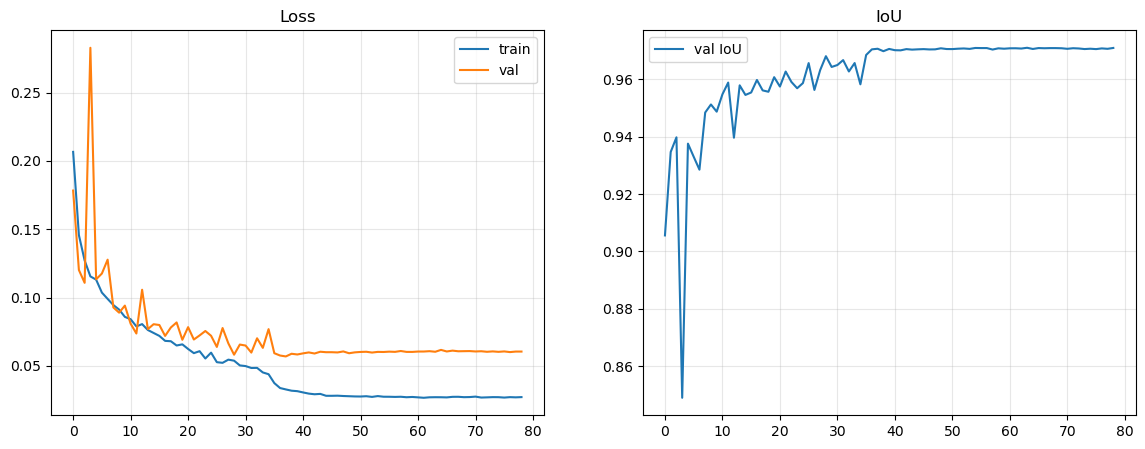

In [13]:
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()
plot_history(history, TrainConfig.OUT_DIR, TrainConfig.VERSION)


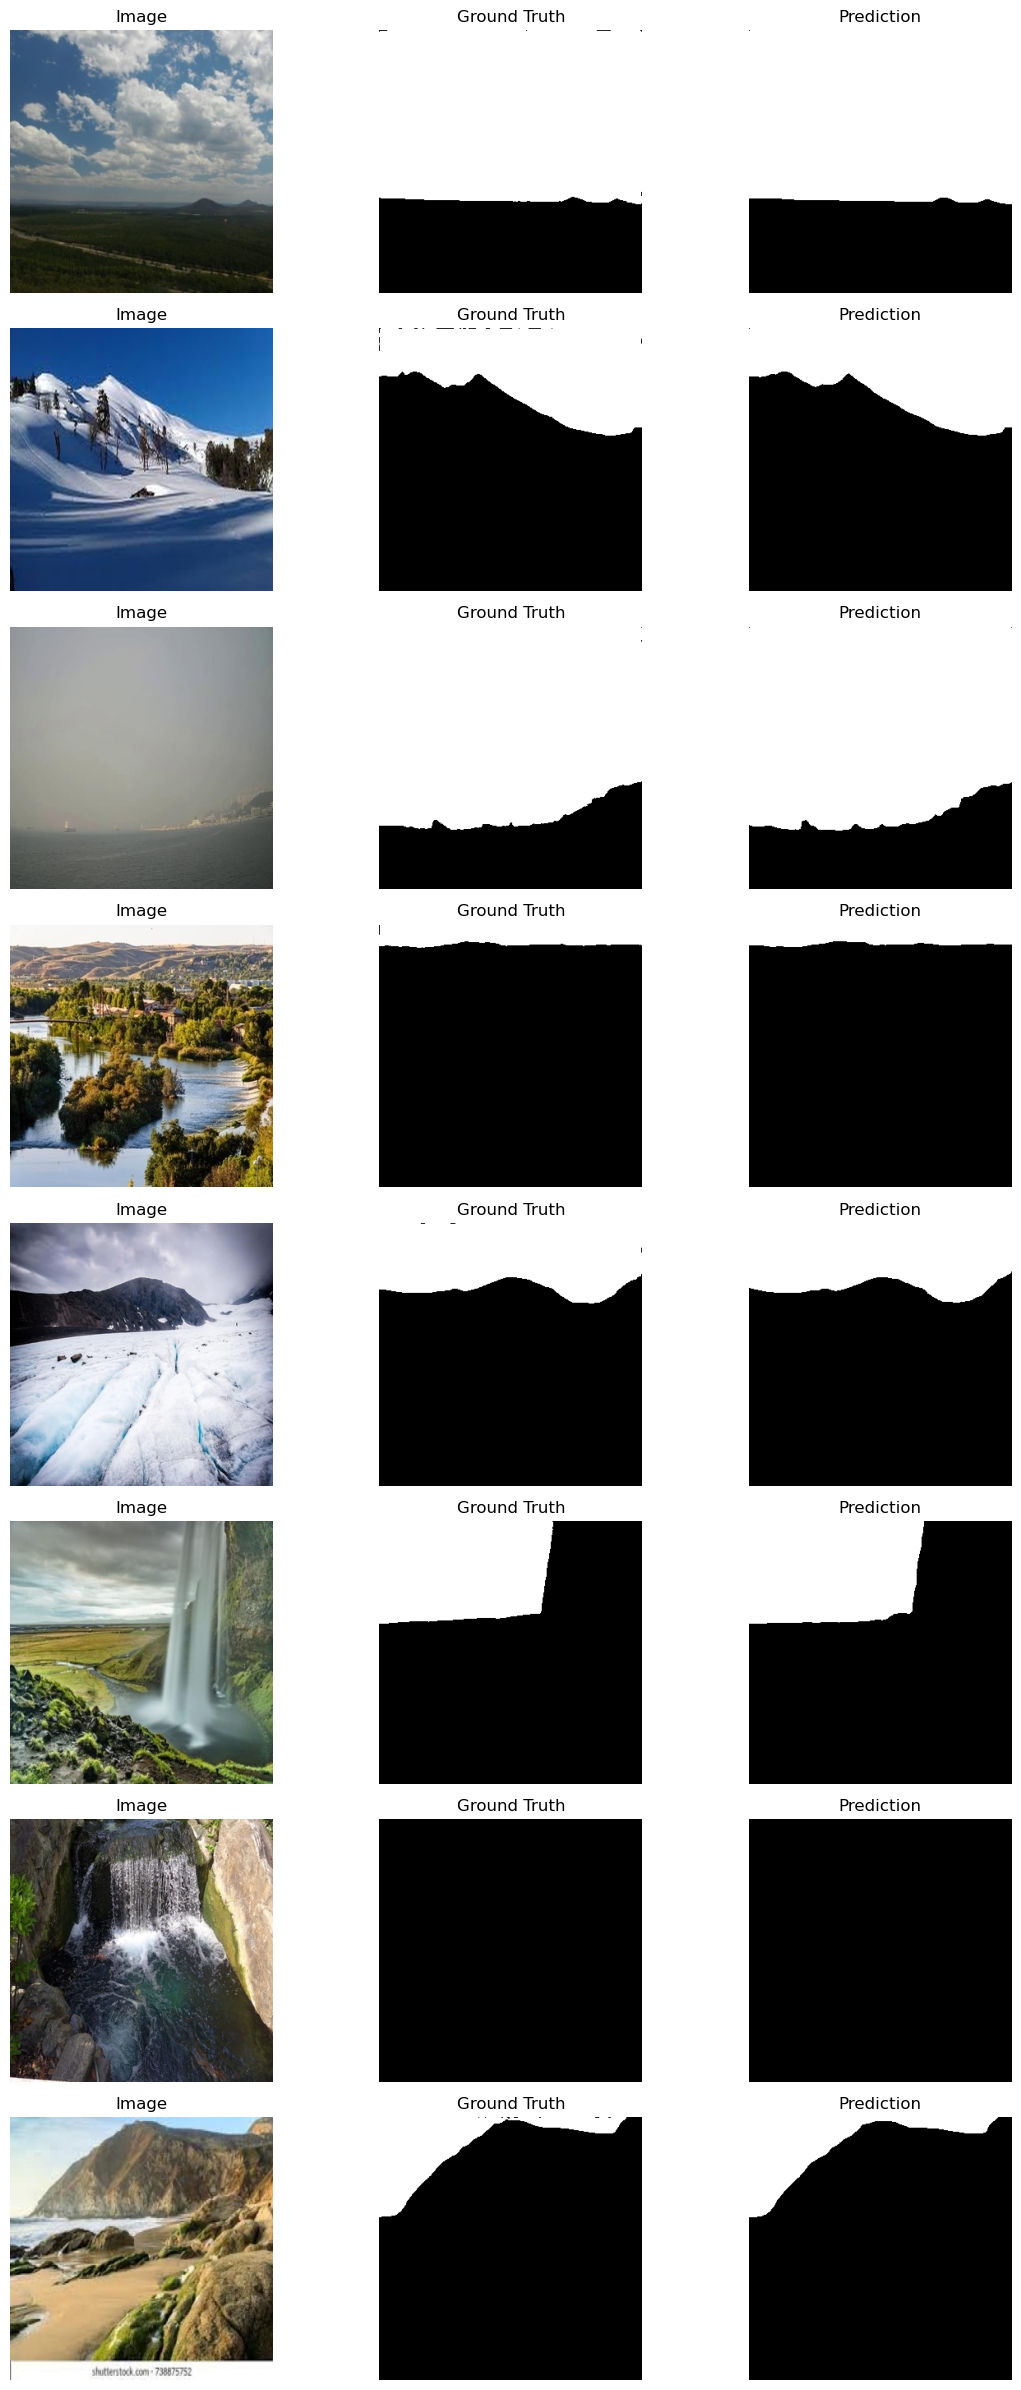

In [14]:
viz_path = str(Path(TrainConfig.OUT_DIR) / f"viz_test_{TrainConfig.VERSION}.png")
visualize_predictions(model, val_loader, num_images=8, save_path=viz_path)

In [15]:
test_running_loss = 0.0
test_running_iou = 0.0

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Evaluating on Test Set"):
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        loss = combined_loss(outputs, masks, TrainConfig.NUM_CLASSES)

        test_running_loss += loss.item()
        test_running_iou += binary_iou(outputs, masks, TrainConfig.NUM_CLASSES)

test_loss = test_running_loss / len(test_loader)
test_iou = test_running_iou / len(test_loader)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test IoU: {test_iou:.4f}")

Evaluating on Test Set: 100%|██████████| 86/86 [00:02<00:00, 28.74it/s]

Test Loss: 0.0551
Test IoU: 0.9726


# ONNX Export

In [16]:
class TrainConfig:
    MANIFEST_CSV = "/home/jovyan/privado/notebooks_jupyter_vinimw/datasets_folder/SAM3_sky_dataset/dataset_sam3_sky_processed/manifest.csv"
    OUT_DIR = f"/home/jovyan/privado/wolosky_notebooks/PyTorch/Unet/Sky_Unet_DeepLab/{VERSION}"
    IMG_SIZE = (320, 320)
    BATCH_SIZE = 32
    EPOCHS = 100
    LR = 1e-3 
    WEIGHT_DECAY = 1e-4
    SEED = 42
    NUM_CLASSES = 1
    TRAIN_FRAC = 0.8
    VAL_FRAC   = 0.1
    TEST_FRAC  = 0.1
    EARLY_STOP_PATIENCE = 15
    REDUCE_LR_PATIENCE = 5
    REDUCE_LR_FACTOR = 0.1
    VERSION = VERSION

In [18]:
import torch
import torch.nn as nn
from pathlib import Path
import numpy as np
from tqdm import tqdm
from onnxruntime.quantization import quantize_dynamic, QuantType
import onnxruntime as ort
import segmentation_models_pytorch as smp

VERSION = TrainConfig.VERSION
OUT_DIR = TrainConfig.OUT_DIR
IMG_SIZE = (320, 320)
NUM_CLASSES = 1

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def get_deeplab_model(num_classes):
    return smp.DeepLabV3Plus(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=num_classes
    )


model = get_deeplab_model(NUM_CLASSES).to(device)
ckpt_path = Path(OUT_DIR) / f"best_model_{VERSION}.pth"
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()


DeepLabV3Plus(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=Tr

In [19]:
class DeepLabTFLiteExport(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)

infer_model = DeepLabTFLiteExport(model).to(device).eval()
dummy_input = torch.randn(1, 3, *TrainConfig.IMG_SIZE, device=device)
onnx_path = Path(TrainConfig.OUT_DIR) / f"{TrainConfig.VERSION}_infer.onnx"

torch.onnx.export(
    infer_model, dummy_input, str(onnx_path),
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    dynamo=False,
)

import onnx
from onnx.external_data_helper import load_external_data_for_model

model_proto = onnx.load(str(onnx_path))
load_external_data_for_model(model_proto, str(onnx_path.parent))
onnx.save(model_proto, str(onnx_path), save_as_external_data=False)

print("ONNX exportado.")

/tmp/ipykernel_15054/2293643340.py:13: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX exportado.


In [20]:
def evaluate_onnx(model_path, loader):
    session = ort.InferenceSession(str(model_path), providers=['CPUExecutionProvider'])
    input_name = session.get_inputs()[0].name
    ious = []
    for images, masks in tqdm(loader, desc="Avaliação ONNX"):
        pred = session.run(None, {input_name: images.numpy()})[0]
        pred_tensor = torch.from_numpy(pred)
        ious.append(binary_iou(pred_tensor, masks, NUM_CLASSES))
    print(f"ONNX IoU Médio: {np.mean(ious):.4f}")

evaluate_onnx(onnx_path, test_loader)

Avaliação ONNX: 100%|██████████| 86/86 [00:28<00:00,  3.00it/s]

ONNX IoU Médio: 0.9726


In [21]:
int8_path = Path(TrainConfig.OUT_DIR) / f"{TrainConfig.VERSION}_infer_int8.onnx"
quantize_dynamic(str(onnx_path), str(int8_path), weight_type=QuantType.QUInt8)
print("ONNX INT8 quantizado.")

ONNX INT8 quantizado.
